In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

print("All libraries loaded successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


All libraries loaded successfully!
NumPy: 2.5.0
Pandas: 3.0.3


In [2]:
import pandas as pd

df = pd.read_csv('Lumos5G-v1.0/Lumos5G-v1.0.csv')

print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
df.head()


Shape: (68118, 19)

Column names:
['run_num', 'seq_num', 'abstractSignalStr', 'latitude', 'longitude', 'movingSpeed', 'compassDirection', 'nrStatus', 'lte_rssi', 'lte_rsrp', 'lte_rsrq', 'lte_rssnr', 'nr_ssRsrp', 'nr_ssRsrq', 'nr_ssSinr', 'Throughput', 'mobility_mode', 'trajectory_direction', 'tower_id']

First 5 rows:


,run_num,seq_num,abstractSignalStr,latitude,longitude,movingSpeed,compassDirection,nrStatus,lte_rssi,lte_rsrp,lte_rsrq,lte_rssnr,nr_ssRsrp,nr_ssRsrq,nr_ssSinr,Throughput,mobility_mode,trajectory_direction,tower_id
0,1,1.0,2,44.975314,-93.259316,0.094889,150,NOT_RESTRICTED,-61.0,-94,-14.0,2.147484e+09,NaN,NaN,NaN,78,driving,CW,16
1,1,2.0,2,44.975311,-93.259311,0.876634,117,NOT_RESTRICTED,-61.0,-94,-14.0,2.147484e+09,NaN,NaN,NaN,117,driving,CW,16
2,1,3.0,2,44.975305,-93.259292,2.225798,113,NOT_RESTRICTED,-61.0,-94,-14.0,2.147484e+09,NaN,NaN,NaN,110,driving,CW,16
3,1,4.0,2,44.975293,-93.259258,3.180726,114,NOT_RESTRICTED,-59.0,-95,-16.0,2.147484e+09,NaN,NaN,NaN,108,driving,CW,16
4,1,5.0,2,44.975278,-93.259214,3.751234,115,NOT_RESTRICTED,-59.0,-95,-16.0,2.147484e+09,NaN,NaN,NaN,100,driving,CW,16


In [3]:
print("Data Info:")
print(df.info())

print("\nBasic Statistics:")
print(df[['Throughput', 'movingSpeed', 'lte_rsrp', 'nr_ssRsrp', 'nr_ssSinr']].describe())

print("\nMobility modes in dataset:")
print(df['mobility_mode'].value_counts())

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 68118 entries, 0 to 68117
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   run_num               68118 non-null  int64  
 1   seq_num               68118 non-null  float64
 2   abstractSignalStr     68118 non-null  int64  
 3   latitude              68118 non-null  float64
 4   longitude             68118 non-null  float64
 5   movingSpeed           68118 non-null  float64
 6   compassDirection      68118 non-null  int64  
 7   nrStatus              68118 non-null  str    
 8   lte_rssi              65137 non-null  float64
 9   lte_rsrp              68118 non-null  int64  
 10  lte_rsrq              65137 non-null  float64
 11  lte_rssnr             65137 non-null  float64
 12  nr_ssRsrp             51990 non-null  float64
 13  nr_ssRsrq             51990 non-null  float64
 14  nr_ssSinr             51990 non-null  float64
 15  Throughput         

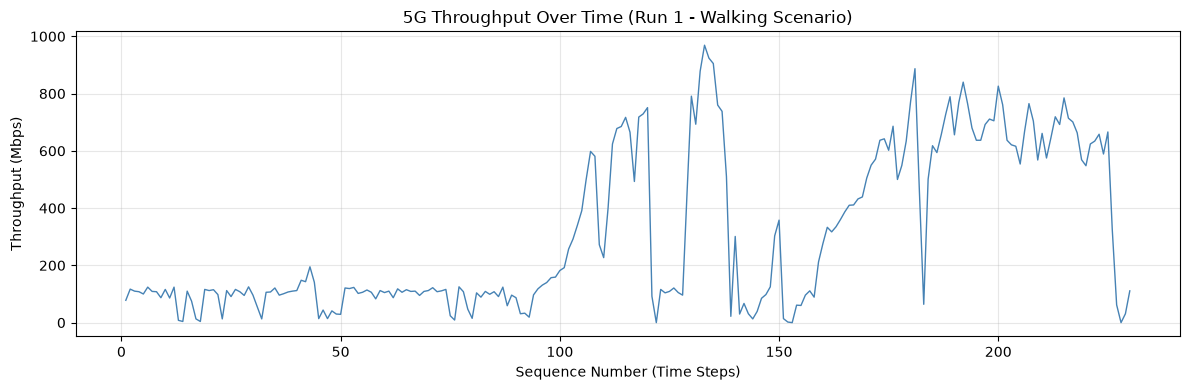

Graph saved!


In [4]:
import matplotlib.pyplot as plt

run1 = df[df['run_num'] == 1]

plt.figure(figsize=(12, 4))
plt.plot(run1['seq_num'], run1['Throughput'], color='steelblue', linewidth=1)
plt.title('5G Throughput Over Time (Run 1 - Walking Scenario)')
plt.xlabel('Sequence Number (Time Steps)')
plt.ylabel('Throughput (Mbps)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('throughput_run1.png', dpi=150)
plt.show()

print("Graph saved!")

In [5]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

features = ['Throughput', 'movingSpeed', 'lte_rsrp', 'lte_rsrq', 'nr_ssRsrp', 'nr_ssRsrq', 'nr_ssSinr']

df_clean = df[features].fillna(0)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nShape:", df_clean.shape)

scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_clean)

print("\nData normalized successfully!")
print("Min values:", df_scaled.min(axis=0))
print("Max values:", df_scaled.max(axis=0))


Missing values after cleaning:
Throughput     0
movingSpeed    0
lte_rsrp       0
lte_rsrq       0
nr_ssRsrp      0
nr_ssRsrq      0
nr_ssSinr      0
dtype: int64

Shape: (68118, 7)

Data normalized successfully!
Min values: [0. 0. 0. 0. 0. 0. 0.]
Max values: [1. 1. 1. 1. 1. 1. 1.]


In [6]:
def create_sequences(data, sequence_length=10):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])  # 10 past steps
        y.append(data[i+sequence_length][0]) # next throughput value
    return np.array(X), np.array(y)

sequence_length = 10
X, y = create_sequences(df_scaled, sequence_length)

print("X shape:", X.shape)  # (samples, timesteps, features)
print("y shape:", y.shape)  # (samples,)
print("\nTotal sequences created:", len(X))

X shape: (68108, 10, 7)
y shape: (68108,)

Total sequences created: 68108


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input shape per sample:", X_train.shape[1:])

Training samples: 54486
Testing samples: 13622
Input shape per sample: (10, 7)


In [8]:
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, output_size=1):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                           batch_first=True, dropout=0.2)
        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, output_size)
    
    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc1(out[:, -1, :])
        out = self.relu(out)
        out = self.fc2(out)
        return out

input_size = X_train.shape[2]  # 7 features
model = LSTMModel(input_size)
print(model)
print("\nModel ready!")

PyTorch version: 2.12.1+cpu
LSTMModel(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)

Model ready!


In [ ]:
from torch.utils.data import DataLoader, TensorDataset

X_train_t = torch.FloatTensor(X_train)
X_test_t = torch.FloatTensor(X_test)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)
y_test_t = torch.FloatTensor(y_test).unsqueeze(1)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Starting training...")
train_losses = []

for epoch in range(20):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        output = model(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/20 - Loss: {avg_loss:.6f}")

print("\nTraining complete!")

Starting training...
Epoch 1/20 - Loss: 0.027494
Epoch 2/20 - Loss: 0.011612
Epoch 3/20 - Loss: 0.009524
Epoch 4/20 - Loss: 0.009093
Epoch 5/20 - Loss: 0.008954
Epoch 6/20 - Loss: 0.008840
Epoch 7/20 - Loss: 0.008757


In [ ]:
torch.save(model.state_dict(), 'lstm_model.pth')
print("Model saved!")

In [ ]:
model.eval()
with torch.no_grad():
    y_pred = model(X_test_t)

y_pred_np = y_pred.numpy().flatten()
y_test_np = y_test_t.numpy().flatten()

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

mse = mean_squared_error(y_test_np, y_pred_np)
mae = mean_absolute_error(y_test_np, y_pred_np)
rmse = np.sqrt(mse)

print("=" * 40)
print("MODEL EVALUATION RESULTS")
print("=" * 40)
print(f"MSE  (Mean Squared Error):  {mse:.6f}")
print(f"RMSE (Root MSE):            {rmse:.6f}")
print(f"MAE  (Mean Absolute Error): {mae:.6f}")

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_np[:300], label='Actual Throughput', color='steelblue', linewidth=1.5)
plt.plot(y_pred_np[:300], label='Predicted Throughput', color='red', linewidth=1.5, linestyle='--')
plt.title('LSTM Predicted vs Actual 5G Throughput')
plt.xlabel('Time Steps')
plt.ylabel('Normalized Throughput')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150)
plt.show()
print("Graph saved!")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, color='green', linewidth=2)
axes[0].set_title('Training Loss Over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].grid(True, alpha=0.3)

errors = y_test_np - y_pred_np
axes[1].hist(errors, bins=50, color='orange', edgecolor='black', alpha=0.7)
axes[1].set_title('Prediction Error Distribution')
axes[1].set_xlabel('Prediction Error')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_loss_and_errors.png', dpi=150)
plt.show()
print("Graph saved!")

In [ ]:
throughput_min = df['Throughput'].min()
throughput_max = df['Throughput'].max()

y_pred_actual = y_pred_np * (throughput_max - throughput_min) + throughput_min
y_test_actual = y_test_np * (throughput_max - throughput_min) + throughput_min

def select_bitrate(predicted_mbps):
    if predicted_mbps >= 500:
        return '6000 Kbps', '1440p', 'Ultra HD'
    elif predicted_mbps >= 200:
        return '3000 Kbps', '1080p', 'Full HD'
    elif predicted_mbps >= 100:
        return '2000 Kbps', '720p', 'HD'
    elif predicted_mbps >= 50:
        return '1000 Kbps', '480p', 'SD'
    else:
        return '500 Kbps', '360p', 'Low'

print("=" * 65)
print(f"{'Time':>4} | {'Predicted (Mbps)':>16} | {'Bitrate':>12} | {'Quality'}")
print("=" * 65)
for i in range(20):
    bitrate, quality, label = select_bitrate(y_pred_actual[i])
    print(f"{i+1:>4} | {y_pred_actual[i]:>16.1f} | {bitrate:>12} | {quality} ({label})")

print("\n" + "=" * 40)
print("BITRATE SELECTION SUMMARY")
print("=" * 40)
bitrates = [select_bitrate(p)[1] for p in y_pred_actual]
from collections import Counter
counts = Counter(bitrates)
total = len(bitrates)
for quality, count in sorted(counts.items()):
    print(f"{quality}: {count} samples ({count/total*100:.1f}%)")

plt.figure(figsize=(14, 5))
plt.plot(y_test_actual[:300], label='Actual Throughput (Mbps)', color='steelblue', linewidth=1.5)
plt.plot(y_pred_actual[:300], label='Predicted Throughput (Mbps)', color='red', linewidth=1.5, linestyle='--')
plt.title('LSTM Predicted vs Actual 5G Throughput (Actual Mbps Scale)')
plt.xlabel('Time Steps')
plt.ylabel('Throughput (Mbps)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('bitrate_adaptation.png', dpi=150)
plt.show()
print("\nGraph saved!")